# Zillow Home Loans: mortgage trends (Jul–Sep 2026) and Q3-26 nowcast

**Signal:** Cotality "Loans over time" monthly loan volume for Zillow Home Loans (`Z`), Rocket (`RKT`) and the total market,
captured weekly with every vintage kept (`BOTS.Z.LOAN_VOLUME_*`).
**Benchmark:** Visible Alpha reported vs consensus (`data/va_benchmarks.csv`, pulled via the audited SRS MCP `kpi_data` action):
total loan origination volume (KPI 14784354), purchase volume (14784355), mortgage revenue (6816280).

Sections:
1. Backtest: how well Cotality volume tracks reported originations
2. Fill-in: how complete the recent months are (vintages)
3. The last 2–3 months: volume, YoY, share of market, Rocket
4. Q3-26 nowcast vs consensus
5. Loan officers: headcount vs productivity
6. Findings

Conclusions use **total loans**. The purchase/refi split is degrading in recent months (unclassified share rises), so it is context only.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display
from common import q, va, backtest_stats, OUT

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

# Reference palette (dataviz skill): fixed categorical order, text in ink tokens
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": MUTED,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False, "lines.linewidth": 2,
})
fmt_bn = mtick.FuncFormatter(lambda x, _: f"${x/1e9:.2f}B")
fmt_mn = mtick.FuncFormatter(lambda x, _: f"${x/1e6:,.0f}M")

def save(fig, name):
    fig.savefig(OUT / f"mortgage_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Backtest: Cotality volume vs reported origination volume

Quarterly **capture rate** = Cotality volume / reported volume. Three out-of-sample estimators (each uses only quarters before the target):

- **T4Q:** signal / trailing 4-quarter average capture rate (the method in `LOAN_VOLUME_BACKTEST`)
- **T1Q:** signal / last quarter's capture rate
- **YoY:** reported a year ago × (1 + signal YoY growth)

Scored on MAPE, bias, and whether the estimate called the beat or miss against consensus correctly.

In [2]:
m = q('''
    select entity, month, month_date, total_loans_volume as vol, total_loan_count as cnt,
           purchase_volume as purch, refinance_volume as refi, capture_timestamp
    from bots.z.loan_volume_monthly_latest
    order by entity, month
''')
m["month_date"] = pd.to_datetime(m["month_date"])
m["quarter"] = m["month_date"].dt.to_period("Q")

sig = (m[m.entity == "Z"].groupby("quarter").agg(signal=("vol", "sum"), months=("vol", "size")))
rep = va("total_orig_volume").set_index("quarter")[["reported", "consensus"]]
bt = sig.join(rep, how="left")
bt = bt[bt.months == 3].copy()           # full quarters only (Q3-26 handled in section 4)
bt["capture"] = bt.signal / bt.reported
done = bt.reported.notna()
cap = bt.capture.where(done)
bt["est_t4q"] = bt.signal / cap.rolling(4, min_periods=1).mean().shift(1)
bt["est_t1q"] = bt.signal / cap.shift(1)
bt["est_yoy"] = bt.reported.shift(4) * (bt.signal / bt.signal.shift(4))

hist = bt[done]
stats = pd.DataFrame({k: backtest_stats(hist, est=f"est_{k}") for k in ["t4q", "t1q", "yoy"]}).T
stats_cons_era = pd.DataFrame({k: backtest_stats(hist.loc["2023Q2":], est=f"est_{k}") for k in ["t4q", "t1q", "yoy"]}).T
print("All quarters with an estimate:")
display(stats.style.format({"n": "{:.0f}", "n_cons": "{:.0f}", "mape": "{:.1%}", "bias": "{:+.1%}",
                            "cons_mape": "{:.1%}", "beat_miss_hit_rate": "{:.0%}"}))
print("Quarters with consensus (2023 Q2 onwards):")
display(stats_cons_era.style.format({"n": "{:.0f}", "n_cons": "{:.0f}", "mape": "{:.1%}", "bias": "{:+.1%}",
                                     "cons_mape": "{:.1%}", "beat_miss_hit_rate": "{:.0%}"}))

tbl = hist[["signal", "reported", "consensus", "capture", "est_t4q"]].copy()
tbl["err_t4q"] = tbl.est_t4q / tbl.reported - 1
tbl["beat_vs_cons"] = tbl.reported / tbl.consensus - 1
display(tbl.loc["2024Q1":].style.format({"signal": "${:,.0f}", "reported": "${:,.0f}", "consensus": "${:,.0f}",
        "capture": "{:.3f}", "est_t4q": "${:,.0f}", "err_t4q": "{:+.1%}", "beat_vs_cons": "{:+.1%}"}, na_rep="–"))

All quarters with an estimate:


,n,mape,bias,cons_mape,beat_miss_hit_rate,n_cons
t4q,17,0.9%,+0.2%,13.1%,100%,13
t1q,17,1.2%,+0.0%,13.1%,100%,13
yoy,14,1.1%,+0.5%,13.1%,100%,13


Quarters with consensus (2023 Q2 onwards):


,n,mape,bias,cons_mape,beat_miss_hit_rate,n_cons
t4q,13,0.9%,+0.3%,13.1%,100%,13
t1q,13,1.2%,-0.0%,13.1%,100%,13
yoy,13,1.1%,+0.5%,13.1%,100%,13


,signal,reported,consensus,capture,est_t4q,err_t4q,beat_vs_cons
quarter,,,,,,,
2024Q1,"$585,708,405","$605,000,000","$457,363,857",0.968,"$610,030,819",+0.8%,+32.3%
2024Q2,"$738,207,062","$759,000,000","$739,599,835",0.973,"$767,417,507",+1.1%,+2.6%
2024Q3,"$790,118,856","$819,000,000","$844,284,286",0.965,"$822,594,546",+0.4%,-3.0%
2024Q4,"$906,582,937","$936,000,000","$818,973,015",0.969,"$939,686,462",+0.4%,+14.3%
2025Q1,"$776,705,553","$796,000,000","$885,090,775",0.976,"$801,962,253",+0.7%,-10.1%
2025Q2,"$1,097,140,346","$1,126,000,000","$993,429,771",0.974,"$1,130,584,980",+0.4%,+13.3%
2025Q3,"$1,238,492,864","$1,281,000,000","$1,177,472,225",0.967,"$1,275,666,387",-0.4%,+8.8%
2025Q4,"$1,481,764,801","$1,550,000,000","$1,341,668,544",0.956,"$1,525,422,688",-1.6%,+15.5%
2026Q1,"$1,529,242,196","$1,570,000,000","$1,217,669,358",0.974,"$1,579,418,336",+0.6%,+28.9%


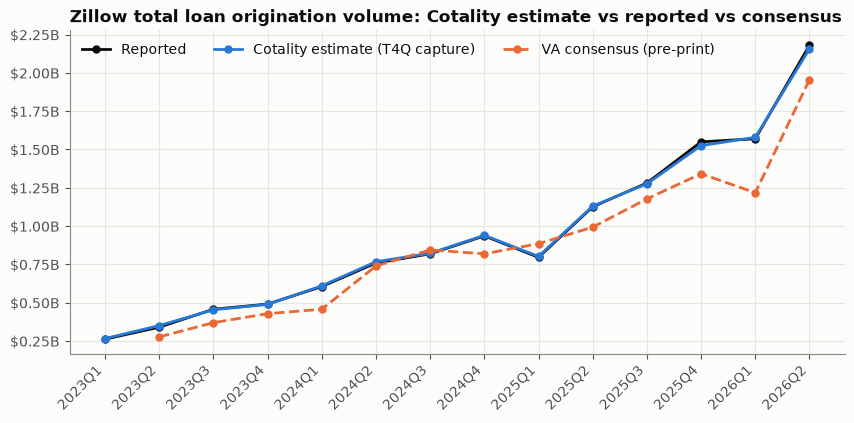

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.2))
x = hist.loc["2023Q1":].index.astype(str)
h = hist.loc["2023Q1":]
ax.plot(x, h.reported, color=INK, marker="o", ms=5, label="Reported")
ax.plot(x, h.est_t4q, color=BLUE, marker="o", ms=5, label="Cotality estimate (T4Q capture)")
ax.plot(x, h.consensus, color=ORANGE, marker="o", ms=5, ls="--", label="VA consensus (pre-print)")
ax.yaxis.set_major_formatter(fmt_bn)
ax.set_title("Zillow total loan origination volume: Cotality estimate vs reported vs consensus")
ax.legend(loc="upper left", ncol=3)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
save(fig, "backtest")

**Caveat: the historical backtest is optimistic.** History uses the *latest*, fully filled-in Cotality data. A live nowcast
is made while the last month or two of the quarter are still filling in. Vintages only start on 2026-08-07, so we can't
replay a true real-time backtest yet. Section 2 measures the fill-in directly and section 4 carries that uncertainty into the Q3 range.

## 2. Fill-in: how complete are Jul, Aug and Sep?

Counties report late, so a month starts small and grows over several weeks. Each vintage is expressed as a share of the
month's latest value, then chained into a **completeness curve** C(lag), the share of final volume visible *lag* days after month-start:
- months with ≥150 days of lag (Apr, May) are treated as final; between 127 and 158 days they still move about ±1% (noise)
- June's curve (lags 67–127) gives C(97), which anchors July's curve (lags 37–97)
- July's curve gives C(66), which anchors August's curve (lags 6–66)
- September has one usable vintage (lag 35). It is bracketed by the July curve (extrapolated) and the August curve.

,Z,Total,RKT
Jul (lag 97),98.8%,97.6%,98.0%
Aug (lag 66),94.2%,90.8%,92.5%
Sep via Jul curve,57.8%,51.7%,52.4%
Sep via Aug curve,50.2%,43.5%,46.8%


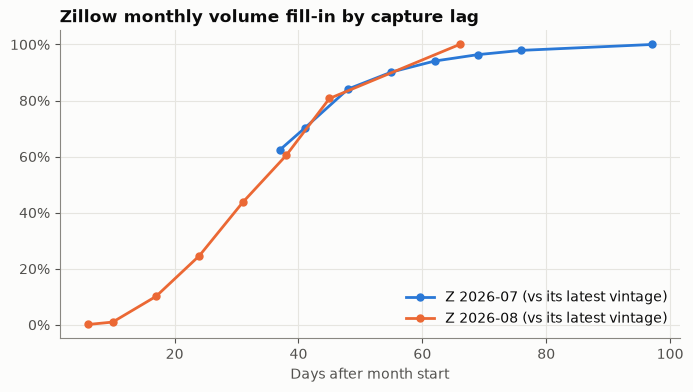

In [4]:
vint = q('''
    select entity, month, capture_timestamp::date as cap_date, max(capture_lag_days) as lag,
           max(total_loans_volume) as vol
    from bots.z.loan_volume_vintages
    where month >= '2026-04'
    group by 1, 2, 3
    order by 1, 2, 3
''')

def curve(e, mo):
    d = vint[(vint.entity == e) & (vint.month == mo)].sort_values("lag")
    return d.lag.to_numpy(float), (d.vol / d.vol.iloc[-1]).to_numpy(float)

def interp(L, xs, ys):
    # linear interpolation, linear extrapolation off the low end (first two points)
    if L < xs[0]:
        return ys[0] + (L - xs[0]) * (ys[1] - ys[0]) / (xs[1] - xs[0])
    return float(np.interp(L, xs, ys))

comp = {}
for e in ["Z", "Total", "RKT"]:
    jx, jy = curve(e, "2026-06"); C_jun = lambda L: interp(L, jx, jy)
    ux, uy = curve(e, "2026-07"); k_jul = C_jun(ux[-1]); C_jul = lambda L: interp(L, ux, uy) * k_jul
    ax_, ay = curve(e, "2026-08"); k_aug = C_jul(ax_[-1]); C_aug = lambda L: interp(L, ax_, ay) * k_aug
    sep_lag = vint[(vint.entity == e) & (vint.month == "2026-09")].lag.max()
    comp[e] = {
        "Jul (lag %d)" % ux[-1]: k_jul,
        "Aug (lag %d)" % ax_[-1]: k_aug,
        "Sep via Jul curve": C_jul(sep_lag),
        "Sep via Aug curve": C_aug(sep_lag),
    }
comp = pd.DataFrame(comp)
display(comp.style.format("{:.1%}").set_caption("Estimated completeness of the latest vintage (share of final volume)"))

fig, ax = plt.subplots(figsize=(8, 4))
for mo, col in [("2026-07", BLUE), ("2026-08", ORANGE)]:
    xs, ys = curve("Z", mo)
    ax.plot(xs, ys, marker="o", ms=5, color=col, label=f"Z {mo} (vs its latest vintage)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Days after month start"); ax.set_title("Zillow monthly volume fill-in by capture lag")
ax.legend(loc="lower right")
save(fig, "fill_curve")

## 3. The last 2–3 months: volume, YoY, share of market, Rocket

Two views:
- **Latest vintage, completeness-adjusted.** Each month's latest value is divided by the section 2 completeness.
- **Like-for-like at matched lag.** Each month is compared with the prior month at the same days of fill. This needs no completeness model.

In [5]:
w = m.pivot_table(index="month", columns="entity", values="vol")
comp_c = comp.loc[:, :]  # rows: Jul, Aug, Sep variants
adj = w.copy()
months = {"2026-07": comp.index[0], "2026-08": comp.index[1]}
for mo, row in months.items():
    for e in ["Z", "Total", "RKT"]:
        adj.loc[mo, e] = w.loc[mo, e] / comp.loc[row, e]
sep_mid = comp.loc[["Sep via Jul curve", "Sep via Aug curve"]].mean()
for e in ["Z", "Total", "RKT"]:
    adj.loc["2026-09", e] = w.loc["2026-09", e] / sep_mid[e]

t = pd.DataFrame({
    "Z latest": w.Z, "Z adj": adj.Z, "Z YoY (adj)": adj.Z / adj.Z.shift(12) - 1,
    "Total adj": adj.Total, "Total YoY (adj)": adj.Total / adj.Total.shift(12) - 1,
    "Z share (latest)": w.Z / w.Total, "Z share (adj)": adj.Z / adj.Total,
    "RKT adj": adj.RKT, "RKT YoY (adj)": adj.RKT / adj.RKT.shift(12) - 1,
}).loc["2026-01":]
display(t.style.format({c: "${:,.0f}" for c in ["Z latest", "Z adj", "Total adj", "RKT adj"]} |
                       {c: "{:+.0%}" for c in t.columns if "YoY" in c} |
                       {"Z share (latest)": "{:.3%}", "Z share (adj)": "{:.3%}"}))

# Like-for-like: each month vs the prior month at the same capture lag (interpolated on the prior month's vintages)
rows = []
for e in ["Z", "Total", "RKT"]:
    for cur, prev in [("2026-08", "2026-07"), ("2026-09", "2026-08")]:
        d = vint[(vint.entity == e) & (vint.month == cur)].sort_values("lag").iloc[-1]
        px = vint[(vint.entity == e) & (vint.month == prev)].sort_values("lag")
        prev_at = interp(d.lag, px.lag.to_numpy(float), px.vol.to_numpy(float))
        ly = m[(m.entity == e)].set_index("month").vol
        ly_mom = ly[str(int(cur[:4]) - 1) + cur[4:]] / ly[str(int(prev[:4]) - 1) + prev[4:]] - 1
        rows.append({"entity": e, "month": cur, "lag": int(d.lag), "MoM at matched lag": d.vol / prev_at - 1,
                     "same MoM last year (final)": ly_mom})
lfl = pd.DataFrame(rows)
display(lfl.style.format({"MoM at matched lag": "{:+.1%}", "same MoM last year (final)": "{:+.1%}"}))

,Z latest,Z adj,Z YoY (adj),Total adj,Total YoY (adj),Z share (latest),Z share (adj),RKT adj,RKT YoY (adj)
month,,,,,,,,,
2026-01,"$383,218,832","$383,218,832",+80%,"$71,175,195,925",+32%,0.538%,0.538%,"$9,356,980,784",+47%
2026-02,"$491,462,219","$491,462,219",+110%,"$78,469,028,259",+41%,0.626%,0.626%,"$9,943,062,746",+59%
2026-03,"$654,561,145","$654,561,145",+98%,"$100,615,159,234",+40%,0.651%,0.651%,"$13,464,209,344",+55%
2026-04,"$668,476,131","$668,476,131",+93%,"$92,973,590,021",+14%,0.719%,0.719%,"$11,918,186,658",+20%
2026-05,"$695,595,540","$695,595,540",+91%,"$87,067,929,729",+4%,0.799%,0.799%,"$11,052,702,172",+19%
2026-06,"$722,977,834","$722,977,834",+87%,"$87,907,429,012",+8%,0.822%,0.822%,"$10,365,939,107",+13%
2026-07,"$684,218,635","$692,745,712",+71%,"$84,054,116,881",+4%,0.834%,0.824%,"$10,329,482,864",+5%
2026-08,"$555,907,535","$589,899,004",+48%,"$75,177,334,393",-7%,0.815%,0.785%,"$9,736,927,980",-6%
2026-09,"$296,021,139","$548,251,258",+26%,"$68,605,052,551",-20%,0.906%,0.799%,"$8,983,638,741",-21%


,entity,month,lag,MoM at matched lag,same MoM last year (final)
0,Z,2026-08,66,-14.8%,-1.7%
1,Z,2026-09,35,+0.0%,+9.6%
2,Total,2026-08,66,-10.6%,+0.2%
3,Total,2026-09,35,-0.2%,+5.8%
4,RKT,2026-08,66,-5.7%,+5.4%
5,RKT,2026-09,35,-2.2%,+10.6%


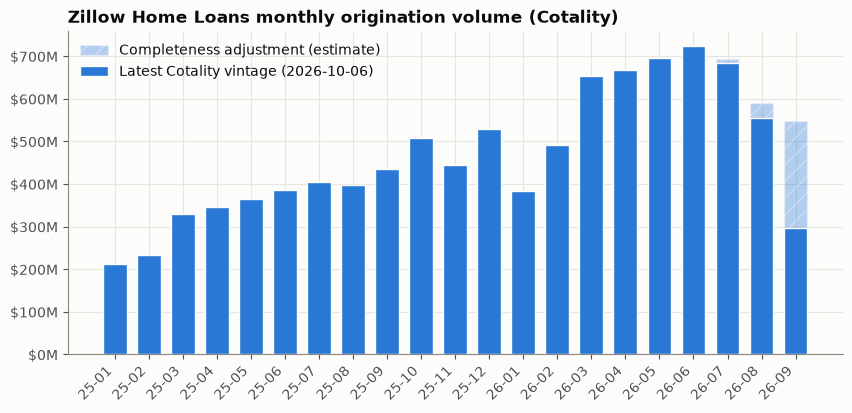

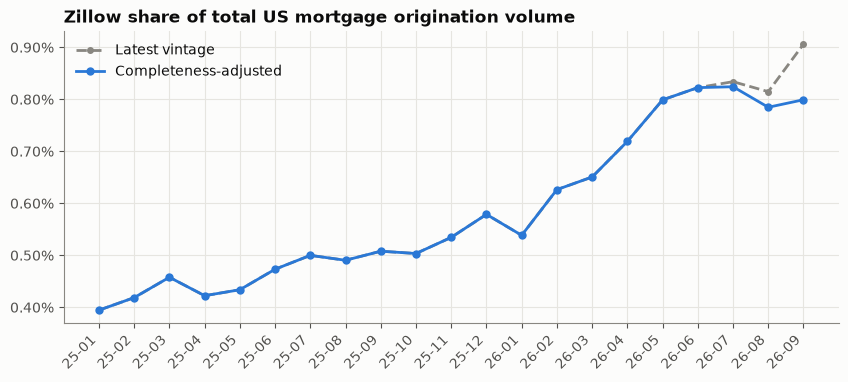

In [6]:
z = t.loc["2025-01":] if "2025-01" in t.index else None
w25 = pd.DataFrame({"latest": w.Z, "adj": adj.Z}).loc["2025-01":]
fig, ax = plt.subplots(figsize=(10, 4.2))
xs = np.arange(len(w25))
ax.bar(xs, w25.adj, width=0.7, color=BLUE, alpha=0.35, hatch="//", edgecolor="#fcfcfb", label="Completeness adjustment (estimate)")
ax.bar(xs, w25.latest, width=0.7, color=BLUE, edgecolor="#fcfcfb", label="Latest Cotality vintage (2026-10-06)")
ax.set_xticks(xs, [s[2:] for s in w25.index], rotation=45, ha="right")
ax.yaxis.set_major_formatter(fmt_mn)
ax.set_title("Zillow Home Loans monthly origination volume (Cotality)")
ax.legend(loc="upper left")
save(fig, "monthly_volume")

fig, ax = plt.subplots(figsize=(10, 3.8))
sh = (pd.DataFrame({"latest": w.Z / w.Total, "adj": adj.Z / adj.Total}).loc["2025-01":])
ax.plot(sh.index.str[2:], sh.latest, color=MUTED, ls="--", marker="o", ms=4, label="Latest vintage")
ax.plot(sh.index.str[2:], sh.adj, color=BLUE, marker="o", ms=5, label="Completeness-adjusted")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=2))
ax.set_title("Zillow share of total US mortgage origination volume")
ax.legend(loc="upper left")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
save(fig, "share")

### Range around the months still filling in (Jul–Sep 26)

The range comes from the completeness assumption. It is a scenario band, not a statistical confidence interval: we have only
three months of fill curves, too few to estimate a distribution.
- **Jul:** ±1pp, the size of the moves still seen in "final" months.
- **Aug:** ±1.5pp, the same band the Q3 nowcast uses.
- **Sep:** between the Jul-curve (57.8%) and Aug-curve (50.2%) completeness.

For scale, the observed spread between months at the same lag is similar: Zillow at about 36 days after month start was
61.6% complete for Jul and 56.9% for Aug.

,latest,completeness,low,central,high,YoY low,YoY central,YoY high
2026-07,"$684,218,635",98.8%,"$685,802,221","$692,745,712","$699,831,241",+69%,+71%,+73%
2026-08,"$555,907,535",94.2%,"$580,656,583","$589,899,004","$599,440,410",+46%,+48%,+51%
2026-09,"$296,021,139",54.0%,"$511,997,695","$548,251,258","$590,030,148",+17%,+26%,+35%


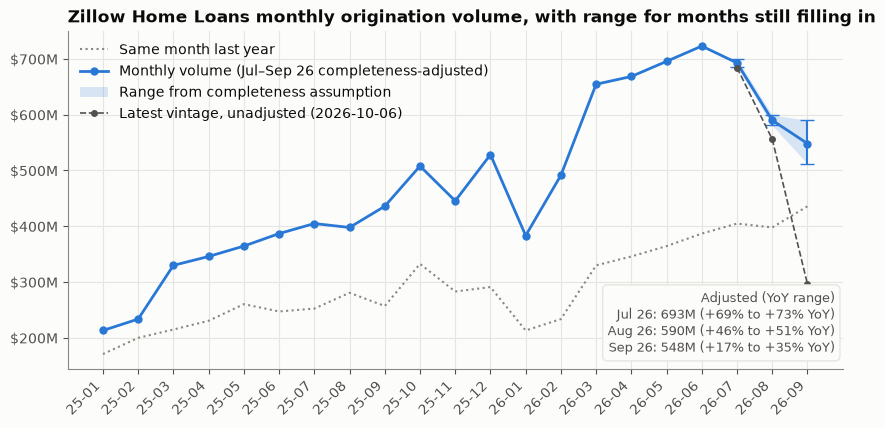

In [7]:
sep_c = comp.loc[["Sep via Jul curve", "Sep via Aug curve"], "Z"]
c_jul_z, c_aug_z = comp.loc[comp.index[0], "Z"], comp.loc[comp.index[1], "Z"]
# (high completeness -> low volume, central, low completeness -> high volume)
c_rng = {"2026-07": (min(c_jul_z + 0.01, 1), c_jul_z, c_jul_z - 0.01),
         "2026-08": (min(c_aug_z + 0.015, 1), c_aug_z, c_aug_z - 0.015),
         "2026-09": (sep_c.max(), sep_mid["Z"], sep_c.min())}
band = pd.DataFrame({mo: {"latest": w.loc[mo, "Z"], "completeness": c[1], "low": w.loc[mo, "Z"] / c[0],
                          "central": w.loc[mo, "Z"] / c[1], "high": w.loc[mo, "Z"] / c[2]}
                     for mo, c in c_rng.items()}).T
ly_m = w.Z.shift(12)
for k in ["low", "central", "high"]:
    band[f"YoY {k}"] = band[k] / ly_m.loc[band.index] - 1
display(band.style.format({c: "${:,.0f}" for c in ["latest", "low", "central", "high"]} | {"completeness": "{:.1%}"}
                          | {c: "{:+.0%}" for c in band.columns if "YoY" in c}))

s = w.Z.loc["2025-01":].copy()
s.loc[band.index] = band.central
xs = np.arange(len(s))
bi = np.array([s.index.get_loc(mo) for mo in band.index])
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(xs, ly_m.loc[s.index], color=MUTED, ls=":", lw=1.5, label="Same month last year")
ax.plot(xs, s.values, color=BLUE, marker="o", ms=5, label="Monthly volume (Jul–Sep 26 completeness-adjusted)")
ax.fill_between(bi, band.low.astype(float), band.high.astype(float), color=BLUE, alpha=0.18, lw=0, label="Range from completeness assumption")
ax.errorbar(bi, band.central.astype(float), yerr=[(band.central - band.low).astype(float), (band.high - band.central).astype(float)],
            fmt="none", ecolor=BLUE, capsize=5, lw=1.5)
ax.plot(bi, band.latest.astype(float), color=INK2, ls="--", marker="o", ms=4, lw=1.2, label="Latest vintage, unadjusted (2026-10-06)")
yoy_txt = "\n".join(f"{pd.Period(mo).strftime('%b %y')}: {band.loc[mo, 'central']/1e6:,.0f}M "
                     f"({band.loc[mo, 'YoY low']:+.0%} to {band.loc[mo, 'YoY high']:+.0%} YoY)" for mo in band.index)
ax.text(0.99, 0.04, "Adjusted (YoY range)\n" + yoy_txt, transform=ax.transAxes, ha="right", va="bottom", fontsize=9,
        color=INK2, bbox=dict(boxstyle="round,pad=0.4", fc="#fcfcfb", ec=GRID))
ax.set_xticks(xs, [i[2:] for i in s.index], rotation=45, ha="right")
ax.yaxis.set_major_formatter(fmt_mn)
ax.set_title("Zillow Home Loans monthly origination volume, with range for months still filling in")
ax.legend(loc="upper left")
save(fig, "monthly_volume_range")

## 4. Q3-26 nowcast vs consensus

Step by step:
1. **What we can see** (2026-10-06 vintage): Jul $684M (97 days after month start), Aug $556M (66 days), Sep $296M (35 days).
2. **Gross up each month by its completeness** (section 2): Jul ÷ 98.8% = $693M; Aug ÷ 94.2% = $590M; Sep ÷ 54.0%
   (midpoint of the Jul-curve 57.8% and Aug-curve 50.2%) = $548M.
3. **Q3 signal:** the sum of the three months, $1.831B. Low case: Sep fills faster (57.8%) and Aug is 1.5pp more complete,
   giving $1.785B. High case: Sep 50.2% and Aug 1.5pp less complete, giving $1.882B.
4. **Convert to Zillow's reported basis:** divide by the trailing-4Q capture rate (0.963, the average of Q3-25 to Q2-26),
   giving a central **$1.90B** (low $1.85B, high $1.95B).
5. **Add capture-rate uncertainty:** divide the low case by the highest capture rate of the last 8 quarters (0.976) and the
   high case by the lowest (0.956). Range **$1.83–1.97B**.
6. **Upper bound that doesn't use the Sep fill model:** assume Aug and Sep equal adjusted July ($693M each), giving
   $2.08B ÷ 0.963 = $2.16B.

In [8]:
cap_t4q = hist.capture.iloc[-4:].mean()
cap_lo, cap_hi = hist.capture.iloc[-8:].min(), hist.capture.iloc[-8:].max()
jul, aug = adj.loc["2026-07", "Z"], adj.loc["2026-08", "Z"]
sep_raw = w.loc["2026-09", "Z"]
sep_hi_c, sep_lo_c = comp.loc[["Sep via Jul curve", "Sep via Aug curve"], "Z"].max(), comp.loc[["Sep via Jul curve", "Sep via Aug curve"], "Z"].min()
# August completeness band: +/-1.5pp around the chained estimate
aug_c = comp.loc[comp.index[1], "Z"]
scen = {
    "Low":     jul + w.loc["2026-08", "Z"] / min(aug_c + 0.015, 1) + sep_raw / sep_hi_c,
    "Central": jul + aug + sep_raw / sep_mid["Z"],
    "High":    jul + w.loc["2026-08", "Z"] / (aug_c - 0.015) + sep_raw / sep_lo_c,
    "Flat at July run-rate": 3 * jul,
}
cons = va("total_orig_volume").set_index("quarter")
c_tot = cons.loc[pd.Period("2026Q3"), "consensus"]
c_pur = va("purchase_orig_volume").set_index("quarter").loc[pd.Period("2026Q3"), "consensus"]
ly = cons.loc[pd.Period("2025Q3"), "reported"]
now = pd.DataFrame({"Q3 signal": pd.Series(scen)})
now["est (T4Q capture)"] = now["Q3 signal"] / cap_t4q
now["est range lo (max capture)"] = now["Q3 signal"] / cap_hi
now["est range hi (min capture)"] = now["Q3 signal"] / cap_lo
now["vs consensus"] = now["est (T4Q capture)"] / c_tot - 1
now["implied YoY"] = now["est (T4Q capture)"] / ly - 1
print(f"T4Q capture {cap_t4q:.3f}; 8Q capture range {cap_lo:.3f}–{cap_hi:.3f}")
print(f"Consensus Q3-26 total {c_tot/1e9:.3f}B (implies {c_tot/ly-1:+.0%} YoY); purchase {c_pur/1e9:.3f}B")
display(now.style.format({c: "${:,.0f}" for c in now.columns[:4]} | {"vs consensus": "{:+.1%}", "implied YoY": "{:+.0%}"}))

# Purchase and mortgage revenue, derived
refi_share = (m[(m.entity == "Z") & (m.month.between("2026-07", "2026-09"))][["refi", "vol"]].sum())
refi_share = refi_share.refi / refi_share.vol
pur_central = now.loc["Central", "est (T4Q capture)"] * (1 - refi_share)
rev = va("mortgage_revenue").set_index("quarter")
take = (rev.reported / cons.reported).dropna().iloc[-4:]
rev_est = now.loc["Central", "est (T4Q capture)"] * take.mean()
c_rev = rev.loc[pd.Period("2026Q3"), "consensus"]
print(f"Purchase (central, refi share {refi_share:.1%} of classified Q3 volume): ${pur_central/1e9:.2f}B vs consensus ${c_pur/1e9:.2f}B ({pur_central/c_pur-1:+.0%})")
print(f"Mortgage revenue (central x trailing-4Q revenue/volume {take.mean():.2%}): ${rev_est/1e6:.0f}M vs consensus ${c_rev/1e6:.0f}M ({rev_est/c_rev-1:+.0%})")

T4Q capture 0.963; 8Q capture range 0.956–0.976
Consensus Q3-26 total 2.275B (implies +78% YoY); purchase 2.236B


,Q3 signal,est (T4Q capture),est range lo (max capture),est range hi (min capture),vs consensus,implied YoY
Low,"$1,785,399,990","$1,853,152,480","$1,829,751,810","$1,867,617,575",-18.5%,+45%
Central,"$1,830,895,973","$1,900,374,949","$1,876,377,978","$1,915,208,646",-16.5%,+48%
High,"$1,882,216,270","$1,953,642,751","$1,928,973,141","$1,968,892,240",-14.1%,+53%
Flat at July run-rate,"$2,078,237,135","$2,157,102,231","$2,129,863,438","$2,173,939,857",-5.2%,+68%


Purchase (central, refi share 1.3% of classified Q3 volume): $1.87B vs consensus $2.24B (-16%)
Mortgage revenue (central x trailing-4Q revenue/volume 3.94%): $75M vs consensus $82M (-9%)


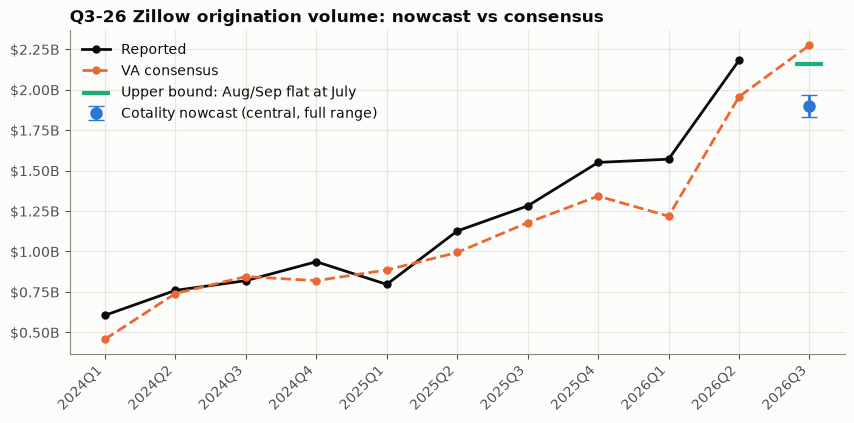

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.2))
h = hist.loc["2024Q1":]
xs = list(h.index.astype(str)) + ["2026Q3"]
ax.plot(xs[:-1], h.reported, color=INK, marker="o", ms=5, label="Reported")
ax.plot(xs, list(h.consensus) + [c_tot], color=ORANGE, marker="o", ms=5, ls="--", label="VA consensus")
lo, hi = now.loc["Low", "est range lo (max capture)"], now.loc["High", "est range hi (min capture)"]
ax.errorbar(["2026Q3"], [now.loc["Central", "est (T4Q capture)"]],
            yerr=[[now.loc["Central", "est (T4Q capture)"] - lo], [hi - now.loc["Central", "est (T4Q capture)"]]],
            fmt="o", ms=8, color=BLUE, capsize=6, lw=2, label="Cotality nowcast (central, full range)")
ax.scatter(["2026Q3"], [now.loc["Flat at July run-rate", "est (T4Q capture)"]], marker="_", s=400, color=AQUA, lw=3,
           label="Upper bound: Aug/Sep flat at July", zorder=5)
ax.yaxis.set_major_formatter(fmt_bn)
ax.set_title("Q3-26 Zillow origination volume: nowcast vs consensus")
ax.legend(loc="upper left")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
save(fig, "q3_nowcast")

### Replay: prior Q3s with the same amount of data we have today

There are no historical vintages (they start 2026-08-07), so this applies **today's fill levels** to each prior Q3's final
monthly data: Jul 98.8%, Aug 94.2%, Sep 54.0% visible. It assumes 2026's fill pace held in prior years. Each Q3 is scored
three ways:
- **Full data:** the backtest in section 1, with no fill lag.
- **Unadjusted:** the partially filled data ÷ T4Q capture, with no gross-up. This is what the
  `cotality_loan_volume_backtest` dashboard does today.
- **Fill-adjusted (our method):** if the fill pace matches our central assumption, this equals the full-data estimate. The
  range shows the error if the true fill sits at either edge of our band: Sep 50.2% or 57.8%, Aug ±1.5pp.

In [10]:
fz = m[m.entity == "Z"].set_index("month").vol
rows = []
for y in [2023, 2024, 2025]:
    J, A, S = (fz[f"{y}-{mm}"] for mm in ["07", "08", "09"])
    r = hist.loc[pd.Period(f"{y}Q3")]
    capq = r.signal / r.est_t4q                                   # T4Q capture used out of sample for that quarter
    raw = (J * c_jul_z + A * c_aug_z + S * sep_mid["Z"]) / capq
    # true fill at the band edge, divided by our central completeness
    slow = (J + A * (c_aug_z - 0.015) / c_aug_z + S * sep_c.min() / sep_mid["Z"]) / capq
    fast = (J + A * min(c_aug_z + 0.015, 1) / c_aug_z + S * sep_c.max() / sep_mid["Z"]) / capq
    beat = r.reported > r.consensus
    rows.append({"quarter": f"{y}Q3", "reported": r.reported, "consensus": r.consensus,
                 "err full data": r.est_t4q / r.reported - 1, "err unadjusted": raw / r.reported - 1,
                 "err adj (slow fill)": slow / r.reported - 1, "err adj (fast fill)": fast / r.reported - 1,
                 "err consensus": r.consensus / r.reported - 1,
                 "beat/miss right: unadjusted": (raw > r.consensus) == beat,
                 "beat/miss right: adj (all cases)": all((e > r.consensus) == beat for e in [slow, r.est_t4q, fast])})
replay = pd.DataFrame(rows).set_index("quarter")
display(replay.style.format({"reported": "${:,.0f}", "consensus": "${:,.0f}"} |
                            {c: "{:+.1%}" for c in replay.columns if c.startswith("err")}))

,reported,consensus,err full data,err unadjusted,err adj (slow fill),err adj (fast fill),err consensus,beat/miss right: unadjusted,beat/miss right: adj (all cases)
quarter,,,,,,,,,
2023Q3,"$457,000,000","$369,533,109",-0.7%,-19.7%,-3.9%,+2.4%,-19.1%,False,True
2024Q3,"$819,000,000","$844,284,286",+0.4%,-17.0%,-2.4%,+3.3%,+3.1%,True,False
2025Q3,"$1,281,000,000","$1,177,472,225",-0.4%,-18.8%,-3.4%,+2.6%,-8.1%,False,True


## 5. Loan officers: headcount vs productivity

`LOAN_OFFICER_PERIOD_PRODUCTIVITY` (monthly). The latest officer capture is 2026-09-18, so it covers **through July 2026**.
July was about 97–98% filled at that capture. The export is capped at 5,000 officers, which Zillow is far below.

,officer_count,total_loans_count,total_loans_volume,loans_per_officer,volume_per_officer,officers YoY,loans/officer YoY
period,,,,,,,
2026-01,308,"1,159","$381,670,054",3.76,"$1,239,188",+50%,+19%
2026-02,328,"1,423","$491,315,917",4.34,"$1,497,914",+58%,+26%
2026-03,346,"1,908","$654,561,145",5.51,"$1,891,795",+54%,+26%
2026-04,388,"2,024","$668,070,689",5.22,"$1,721,832",+60%,+24%
2026-05,391,"2,042","$691,390,572",5.22,"$1,768,262",+66%,+14%
2026-06,427,"2,211","$718,337,289",5.18,"$1,682,289",+76%,+8%
2026-07,419,"1,994","$671,480,829",4.76,"$1,602,580",+69%,-3%


,loan count YoY,from headcount,from productivity
period,,,
2026-05,+89%,80%,20%
2026-06,+91%,87%,13%
2026-07,+64%,106%,-6%


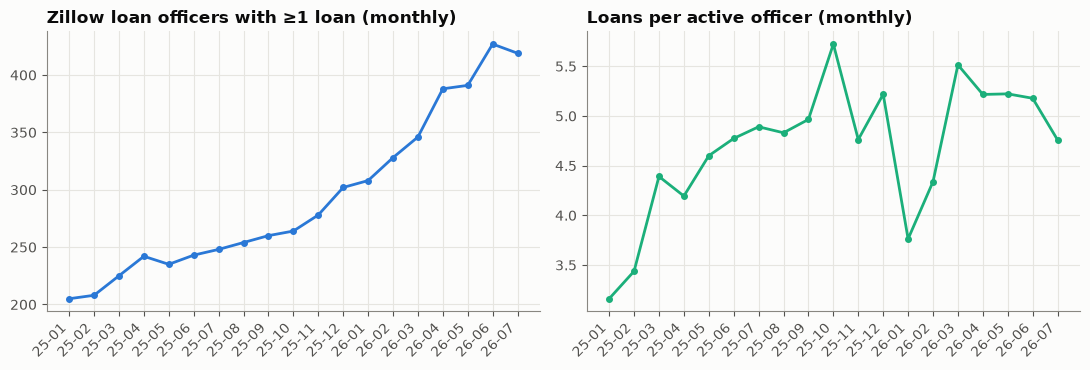

In [11]:
lo_df = q('''
    select period, officer_count, total_loans_count, total_loans_volume, loans_per_officer, volume_per_officer
    from bots.z.loan_officer_period_productivity
    where entity = 'Z' and period_type = 'M' and period >= '2025-01'
    order by period
''').set_index("period").astype(float)
lo_df["officers YoY"] = lo_df.officer_count / lo_df.officer_count.shift(12) - 1
lo_df["loans/officer YoY"] = lo_df.loans_per_officer / lo_df.loans_per_officer.shift(12) - 1
display(lo_df.loc["2026-01":].style.format({"officer_count": "{:,.0f}", "total_loans_count": "{:,.0f}", "total_loans_volume": "${:,.0f}", "volume_per_officer": "${:,.0f}",
        "loans_per_officer": "{:.2f}", "officers YoY": "{:+.0%}", "loans/officer YoY": "{:+.0%}"}, na_rep="–"))

# Decompose YoY loan-count growth into headcount and productivity (log shares)
d = lo_df.loc[["2026-05", "2026-06", "2026-07"]].copy()
prev = lo_df.loc[["2025-05", "2025-06", "2025-07"]]
g_off = np.log(d.officer_count.to_numpy() / prev.officer_count.to_numpy())
g_lpo = np.log(d.loans_per_officer.to_numpy() / lo_df.loc[["2025-05", "2025-06", "2025-07"], "loans_per_officer"].to_numpy())
dec = pd.DataFrame({"loan count YoY": np.exp(g_off + g_lpo) - 1, "from headcount": g_off / (g_off + g_lpo),
                    "from productivity": g_lpo / (g_off + g_lpo)}, index=d.index)
display(dec.style.format({"loan count YoY": "{:+.0%}", "from headcount": "{:.0%}", "from productivity": "{:.0%}"}))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
x = lo_df.index.str[2:]
axes[0].plot(x, lo_df.officer_count, color=BLUE, marker="o", ms=4)
axes[0].set_title("Zillow loan officers with ≥1 loan (monthly)")
axes[1].plot(x, lo_df.loans_per_officer, color=AQUA, marker="o", ms=4)
axes[1].set_title("Loans per active officer (monthly)")
for a in axes:
    plt.setp(a.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()
save(fig, "officers")

## 6. Findings

**1. The signal is strong.** Cotality captures a stable 96–98% of reported Zillow origination volume (T4Q capture 0.963).
Out-of-sample, the T4Q estimate has **0.9% MAPE** (T1Q 1.2%, YoY 1.1%) against **13.1% for consensus**. It called the beat or miss
correctly in **13/13** quarters since consensus began (2023 Q2). This uses fully filled data, so a live nowcast is less precise;
the fill-in uncertainty is carried into the Q3 range below.

**2. Momentum faded over the last 2–3 months.** Completeness-adjusted Zillow volume (in brackets, the latest vintage's completeness):
- **Jul about $693M (+71% YoY)**, near final (99%)
- **Aug about $590M (+48%)** (94%)
- **Sep about $550M (+26%)**, very provisional (50–58%)

YoY growth was +87–93% from Apr to Jun. Like-for-like at matched lag, Aug was **−15% vs Jul**, against −2% in the same month last
year, and Sep was flat vs Aug against +10% last year. Part of the Aug drop is market-wide: total-market volume at matched lag
was −11% vs +0% last year.

**3. Market share has stalled.** Zillow's share of US origination volume rose from 0.54% (Jan) to **0.82–0.83% (Jun–Jul)**,
then the adjusted figure fell to **about 0.79% in Aug and Sep**. Raw recent-month shares overstate it (Sep reads 0.91%) because
Zillow's loans fill in faster than the total market's. Rocket's YoY swung from +13% (Jun) to about −6% (Aug), so the slowdown is not unique to Zillow.

**4. The Q3-26 nowcast points to a material miss on origination volume.**

| Case | Estimate | vs consensus ($2.27B) | Implied YoY |
|---|---|---|---|
| Central | **$1.90B** | **−16%** | +48% (consensus implies +78%) |
| Range (Sep fill × capture rate) | $1.83–1.97B | −19% to −13% | |
| Aug and Sep flat at July's run-rate (upper bound) | $2.16B | −5% | |

Purchase volume is about $1.87B vs $2.24B consensus. Mortgage revenue, derived as volume × revenue per $ originated, is about
**$75M vs $82M consensus (−9%)**. Rate and margin can offset part of the volume gap.

**5. Growth has been headcount-led, and that stalled in July.** The officer data runs through Jul-26. Active officers rose from
308 (Jan) to 427 (Jun), then 419 in Jul. Loans per officer fell to 4.76 in Jul (−3% YoY; Jul about 98% filled). July's +64% YoY
loan count was entirely headcount; productivity was negative. This fits the Notion finding that new officers take 6–9 months to ramp.

**6. Fill lag is the main live risk, and adjusting for it matters.** Replaying Q3-23, Q3-24 and Q3-25 with today's fill levels:
- **Unadjusted** (the `cotality_loan_volume_backtest` dashboard method): errors of **−17% to −20%**. It would have called
  Q3-23 and Q3-25 as misses when both beat.
- **Fill-adjusted:** errors of **−3.9% to +3.3%** across the fill band, against 0.4–0.8% with full data.

The beat/miss call holds across the band except at the fast-fill edge for Q3-24, where consensus was only 3% above reported.
That dashboard's +24.5% YoY Q3 nowcast ($1.59B) is the unadjusted number: Sep is about 54% filled and Aug about 94%.

**Caveats**
- September is only about 35 days filled, and its completeness is model-based (two curves bracket it).
- The weekly captures on 09-22 and 09-29 were missed, which leaves gaps in the vintage history.
- The historical capture rate could shift if Zillow's channel mix changes.
- The purchase/refi split is unreliable in recent months (unclassified share was 29% for Jul at the latest vintage).
- Re-run after the next Tuesday capture: Aug should be about 97% complete and Sep about 75–80%.